<a href="https://colab.research.google.com/github/Saxon-account/vhs-intro-ai/blob/main/handwriting_recognition/mnist_digit_recognition_cnn_Meznarich.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Neural Network

In [2]:
import tensorflow as tensorflow #(This)
from tensorflow import keras
keras.datasets.mnist.load_data(path="mnist.npz")
#Plotting
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")
#Matplotlib defaults
plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('animation', html='html5')
import pandas as pd
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.model_selection import GroupShuffleSplit

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import callbacks

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
(X_train, y_train), (X_valid, y_valid) = keras.datasets.mnist.load_data()
assert X_train.shape == (60000, 28, 28)
assert X_valid.shape == (10000, 28, 28)
assert y_train.shape == (60000,)
assert y_valid.shape == (10000,)

import numpy as np
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, 10)
y_valid = to_categorical(y_valid, 10)

X_train = X_train.reshape(60000, 784)
X_valid = X_valid.reshape(10000, 784)

In [4]:
X_train = X_train.astype("float32") / 255
X_valid = X_valid.astype("float32") / 255

In [5]:
from tensorflow.keras import layers

input_shape = (784,)

#Regular Model:
#16 neurons, 1 hidden layer
model1 = keras.Sequential([
    layers.BatchNormalization(input_shape=input_shape),
    layers.Dense(16, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(rate=0.3),
    layers.Dense(10, activation='softmax'),
])

model1.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)
model1.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/normalization/batch_normalization.py:142: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ batch_normalization                  │ (None, 784)                 │           3,136 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │          12,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 16)                  │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             170 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,930 (62.23 KB)

 Trainable params: 14,330 (55.98 KB)

 Non-trainable params: 1,600 (6.25 KB)

Epoch 1/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9138 - loss: 0.2768 - val_accuracy: 0.9417 - val_loss: 0.2038
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9142 - loss: 0.2798 - val_accuracy: 0.9423 - val_loss: 0.2017
Epoch 3/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9160 - loss: 0.2723 - val_accuracy: 0.9423 - val_loss: 0.2031
Epoch 4/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9135 - loss: 0.2787 - val_accuracy: 0.9431 - val_loss: 0.1983
Epoch 5/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9155 - loss: 0.2726 - val_accuracy: 0.9427 - val_loss: 0.2001
Epoch 6/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9126 - loss: 0.2806 - val_accuracy: 0.9418 - val_loss: 0.2029
Epoch 7/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9148 - loss: 0.2759 - val_accuracy: 0.9432 - val_loss: 0.2009
Epoch 8/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9146 - loss: 0.2818 - val_accuracy: 0.9421 - v

<Axes: title={'center': 'Accuracy (Adam)'}>

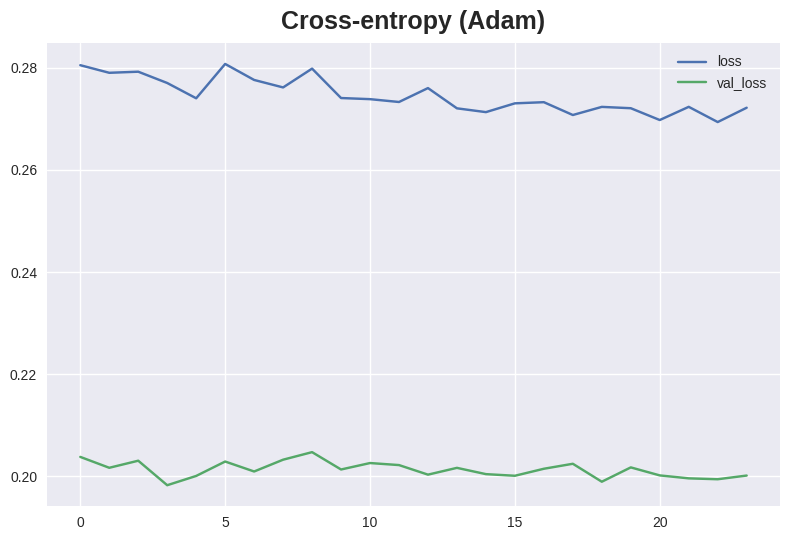

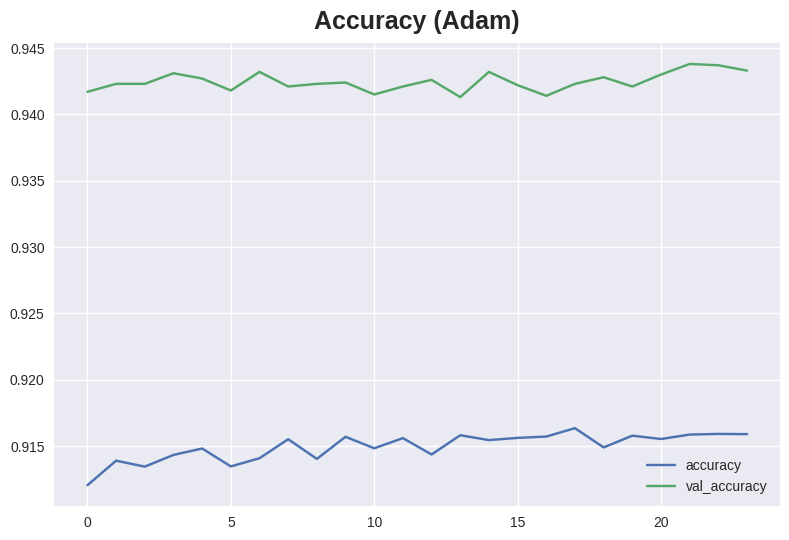

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    min_delta=0.001, # 0.001 minimium amount of change to count as an improvement
    patience=20, # how many epochs to wait before stopping
    restore_best_weights=True,
)

history = model1.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=1000,
    epochs=30,
    callbacks=[early_stopping],
)

history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy (Adam)")
history_df.loc[:, ['accuracy', 'val_accuracy']].plot(title="Accuracy (Adam)")

In [11]:
model1.save_weights('mnist_nn.weights.h5', overwrite=True)

#Convolutional Neural Network

In [13]:
(X_train, y_train), (X_valid, y_valid) = keras.datasets.mnist.load_data()
assert X_train.shape == (60000, 28, 28)
assert X_valid.shape == (10000, 28, 28)
assert y_train.shape == (60000,)
assert y_valid.shape == (10000,)

import numpy as np
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, 10)
y_valid = to_categorical(y_valid, 10)

In [14]:
X_train = X_train.astype("float32") / 255
X_valid = X_valid.astype("float32") / 255

In [15]:
X_train = np.expand_dims(X_train, -1)
X_valid = np.expand_dims(X_valid, -1)
print("X train shape: ", X_train.shape)
print(X_train.shape[0], "train samples")
print(X_valid.shape[0], "valid samples")

X train shape:  (60000, 28, 28, 1)
60000 train samples
10000 valid samples


In [16]:
input_shape = (28, 28, 1)

model_cnn = keras.Sequential([
    keras.Input(shape=input_shape),
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

In [17]:
model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │          16,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 48s 778ms/step - accuracy: 0.5096 - loss: 1.5909 - val_accuracy: 0.9274 - val_loss: 0.2615
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 82s 770ms/step - accuracy: 0.9131 - loss: 0.2870 - val_accuracy: 0.9623 - val_loss: 0.1336
Epoch 3/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 84s 806ms/step - accuracy: 0.9482 - loss: 0.1728 - val_accuracy: 0.9728 - val_loss: 0.0938
Epoch 4/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 45s 748ms/step - accuracy: 0.9601 - loss: 0.1319 - val_accuracy: 0.9769 - val_loss: 0.0764
Epoch 5/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 82s 753ms/step - accuracy: 0.9660 - loss: 0.1099 - val_accuracy: 0.9795 - val_loss: 0.0653
Epoch 6/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 82s 756ms/step - accuracy: 0.9711 - loss: 0.0958 - val_accuracy: 0.9820 - val_loss: 0.0580
Epoch 7/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 81s 734ms/step - accuracy: 0.9743 - loss: 0.0868 - val_accuracy: 0.9828 - val_loss: 0.0526
Epoch 8/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 85s 786ms/step - accuracy: 0.9751 - loss: 0.0819 - val_accu

<Axes: title={'center': 'Accuracy (Adam)'}>

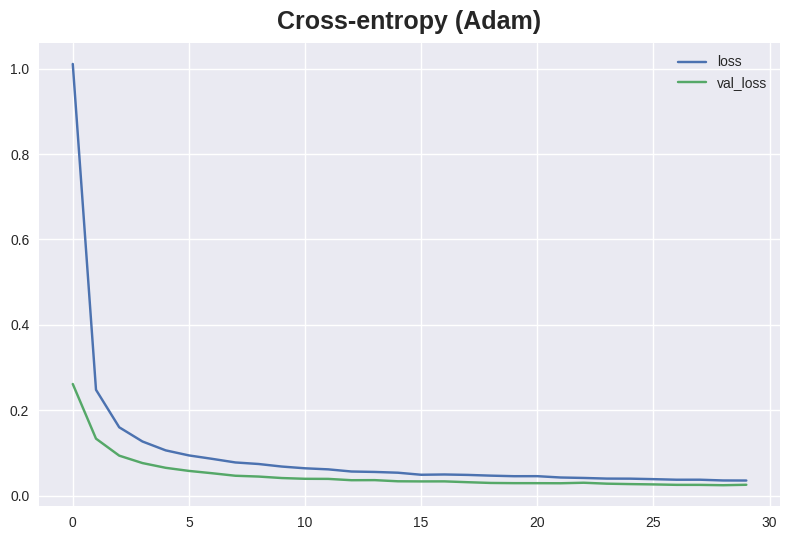

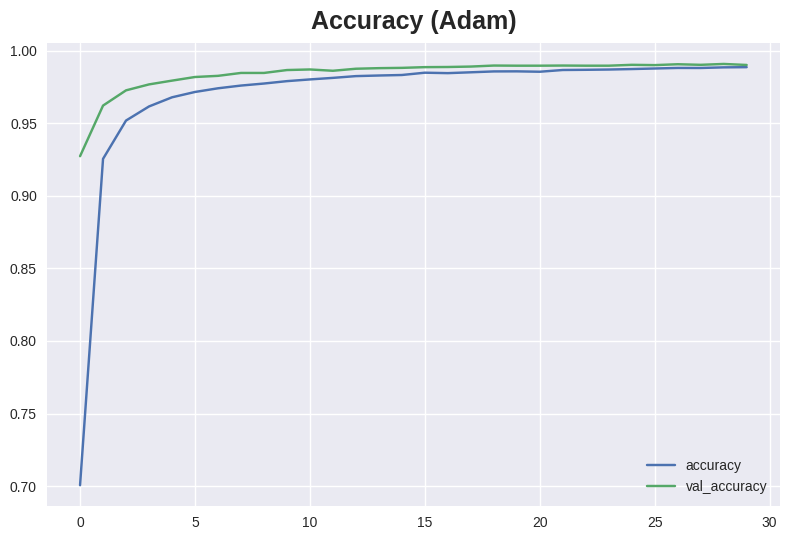

In [18]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    min_delta=0.001, # 0.001 minimium amount of change to count as an improvement
    patience=20, # how many epochs to wait before stopping
    restore_best_weights=True,
)

history = model_cnn.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=1000,
    epochs=30,
    callbacks=[early_stopping],
)

history_df = pd.DataFrame(history.history)
history_df.loc[:, ['loss', 'val_loss']].plot(title="Cross-entropy (Adam)")
history_df.loc[:, ['accuracy', 'val_accuracy']].plot(title="Accuracy (Adam)")

In [19]:
model_cnn.save_weights('mnist_cnn.weights.h5', overwrite=True)

#Comparing the 2 Models

##1. Data handling

**NN:**

accuracy: 0.9170, loss: 0.2708,

val_accuracy: 0.9433, val_loss: 0.2002

**CNN:**

accuracy: 0.9894, loss: 0.0341, val_accuracy: 0.9903,

val_loss: 0.0256

CNN has a significantly higher accuracy and validation accuracy than NN with a much lower loss and validation loss, simply a more accurate model overall.


##2. Parameter sharing

CNN utilizes parameter sharing when filtering the input channel(s). Allows the model to reduce amount of parameters it must learn across every convolutional layer. CNNs generally can make accurate predictions with a limited number of parameters because of this.

NN does not use parameter sharing

##3. Training time

**NN:** training time per epoch: ~1 second

**CNN:** training time per epoch: ~82 seconds

CNN has significantly longer training time due to the amount of time it takes for convolutions and max pooling, processing many more parameters.

##4. Number of parameters trained (including weights and biases)

In [20]:
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ batch_normalization                  │ (None, 784)                 │           3,136 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │          12,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 16)                  │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             170 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 44,592 (174.19 KB)

 Trainable params: 14,330 (55.98 KB)

 Non-trainable params: 1,600 (6.25 KB)

 Optimizer params: 28,662 (111.96 KB)

In [21]:
model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │          16,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 104,480 (408.13 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 69,654 (272.09 KB)

Parameters: CNN: 104,480 > NN: 44,592

CNN has a larger amount of parameters due to kernal size and convolutional layers having multiple filters which extract multiple features from each image and assigned them to parameters.

Both 2D convolutional layers have 32 and 64 filters respectively, effecting the number of parameters of each:


**Number of Weights per Filter** = filter dimensions x input


**Number of Parameters** = (filter dimensions x input channels+1) x number of filters
channels

*+1 is the bias*

(3 x 3 x 1 +1) x 32 = 320

This produces 32 output channels that the next layer uses as input channels

(3 x 3 x 32 +1) x 64 = 18,496

(320, 18,496)

CNN has 0 Non-trainable parameters whereas NN has 1,600, meaning CNN has no weights that aren't being updated each epoch.
